In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../olist.db")

query = """
WITH entregas AS (
    SELECT
        o.order_id,
        julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date) AS dias_retraso,
        AVG(r.review_score) AS score
    FROM orders o
    JOIN reviews r ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY o.order_id
)
SELECT
    CASE
        WHEN dias_retraso <= 0 THEN 'A tiempo'
        WHEN dias_retraso <= 3 THEN '1-3 días'
        WHEN dias_retraso <= 7 THEN '4-7 días'
        ELSE '+7 días'
    END AS grupo,
    COUNT(*) AS ordenes,
    ROUND(AVG(score), 2) AS calificacion
FROM entregas
GROUP BY grupo;
"""

df = pd.read_sql(query, conn)
orden = ["A tiempo", "1-3 días", "4-7 días", "+7 días"]
df = df.set_index("grupo").loc[orden].reset_index()
df

Matplotlib is building the font cache; this may take a moment.


,grupo,ordenes,calificacion
0,A tiempo,88163,4.29
1,1-3 días,2636,3.77
2,4-7 días,1773,2.32
3,+7 días,3252,1.73


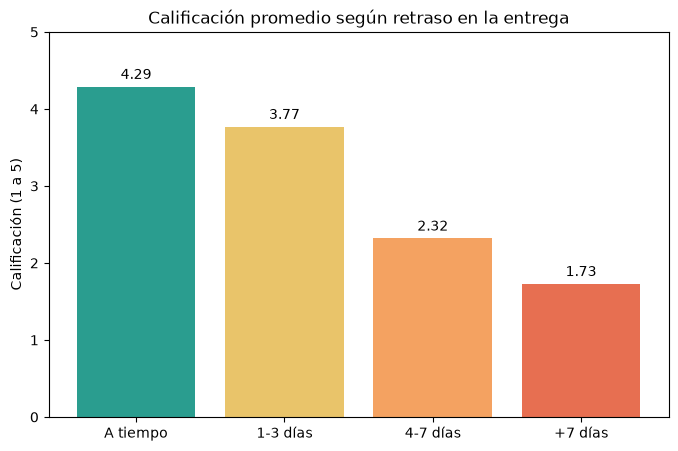

In [2]:
plt.figure(figsize=(8, 5))
plt.bar(df["grupo"], df["calificacion"], color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
plt.title("Calificación promedio según retraso en la entrega")
plt.ylabel("Calificación (1 a 5)")
plt.ylim(0, 5)
for i, v in enumerate(df["calificacion"]):
    plt.text(i, v + 0.1, str(v), ha="center")
plt.show()

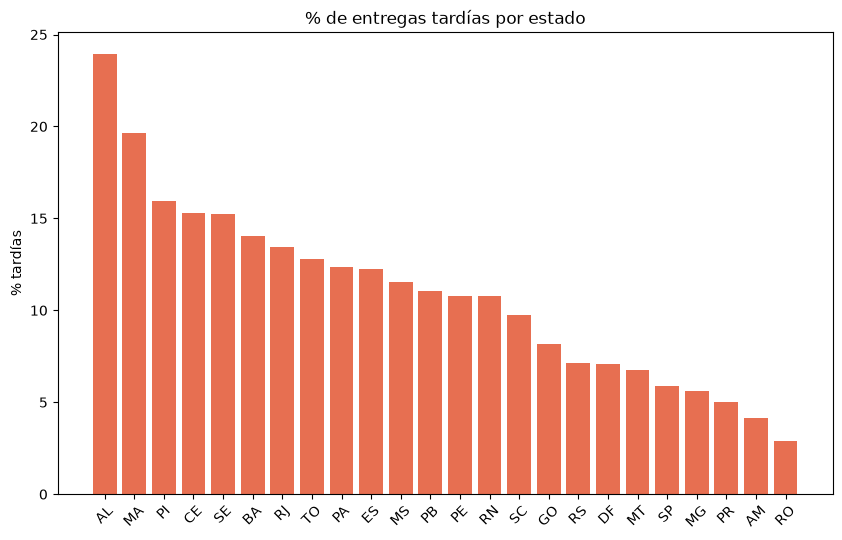

In [8]:
query_estado = """
SELECT
    c.customer_state AS estado,
    COUNT(*) AS ordenes,
    ROUND(100.0 * SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_tardias
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = "delivered"
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
HAVING count (*) >= 100
ORDER BY pct_tardias DESC;
"""

df_estado = pd.read_sql(query_estado, conn)

plt.figure(figsize=(10, 6))
plt.bar(df_estado["estado"], df_estado["pct_tardias"], color="#e76f51")
plt.title("% de entregas tardías por estado")
plt.ylabel("% tardías")
plt.xticks(rotation=45)
plt.show()

import os 
os.makedirs("../dashboard", exist_ok=True)
df.to_csv("../dashboard/calificacion_vs_retrasi.csv", index=False)
df_estado.to_csv("../dashboard/retrasos_por_estado.csv", index=False)